In [1]:
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("amz_uk_price_prediction_dataset.csv")
df.head(10)

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
5,6,B09B97WSLF,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
6,7,B09B9615X2,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
7,8,B01MTB55WH,Anker Soundcore 2 Portable Bluetooth Speaker w...,4.7,103673,39.99,False,0,Hi-Fi Speakers
8,9,B016MO90GW,"Bluetooth Speaker, Anker Soundcore Speaker Upg...",4.7,29909,29.99,False,0,Hi-Fi Speakers
9,10,B09ZQF5GZW,RIENOK Bluetooth Speaker Portable Wireless Blu...,4.5,16014,29.99,False,0,Hi-Fi Speakers


In [2]:
df.shape

(2443651, 9)

In [3]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

In [6]:
df.dtypes

uid                    int64
asin                  object
title                 object
stars                float64
reviews                int64
price                float64
isBestSeller            bool
boughtInLastMonth      int64
category              object
dtype: object

In [6]:
df.duplicated().sum()

np.int64(0)

**Part 1: Understanding Product Categories**
Business Question: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

In [7]:
df['category'].value_counts()

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Motorbike Chassis                            107
Alexa Built-In Devices                       107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [8]:
df['category'].value_counts().nunique()

246

**Frequency Tables:**
Generate a frequency table for the product category.

In [9]:
category_freq_table = df['category'].value_counts()

In [10]:
category_freq_table

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Motorbike Chassis                            107
Alexa Built-In Devices                       107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

Which are the top 5 most listed product categories?

In [11]:
print("Top 5 most listed product categories")
category_freq_table.head(5)

Top 5 most listed product categories


category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

**Visualizations:**
Display the distribution of products across different categories using a bar chart. If you face problems understanding the chart, do it for a subset of top categories.

In [23]:
df['category'].unique()

array(['Hi-Fi Speakers', 'CD, Disc & Tape Players', 'Wearable Technology',
       'Light Bulbs', 'Bathroom Lighting',
       'Heating, Cooling & Air Quality', 'Coffee & Espresso Machines',
       'Lab & Scientific Products', 'Smart Speakers',
       'Motorbike Clothing', 'Motorbike Accessories',
       'Motorbike Batteries', 'Motorbike Boots & Luggage',
       'Motorbike Chassis', 'Handmade Home & Kitchen Products',
       'Hardware', 'Storage & Home Organisation',
       'Fireplaces, Stoves & Accessories', 'PC Gaming Accessories',
       'USB Gadgets', 'Blank Media Cases & Wallets', 'Car & Motorbike',
       'Boys', 'Sports & Outdoors', 'Microphones', 'String Instruments',
       'Karaoke Equipment', 'PA & Stage',
       'General Music-Making Accessories', 'Wind Instruments',
       'Handmade Gifts', 'Fragrances', 'Calendars & Personal Organisers',
       'Furniture & Lighting', 'Computer Printers', 'Ski Goggles',
       'Snowboards', 'Skiing Poles', 'Downhill Ski Boots',
       'Hiki

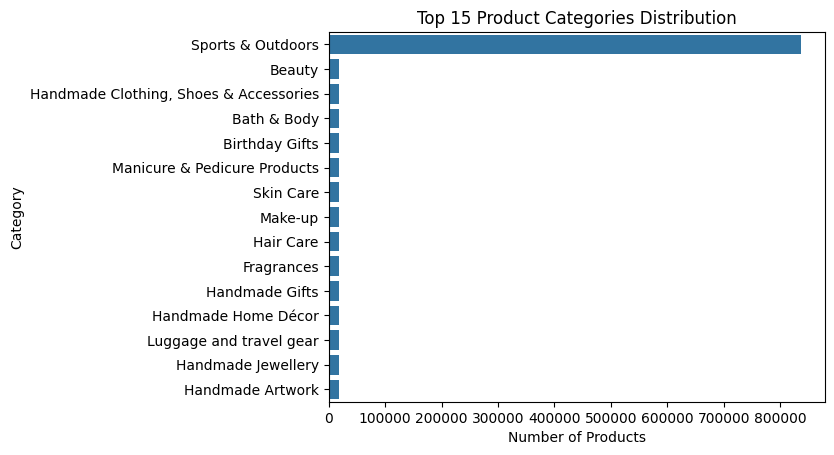

In [12]:
import matplotlib.pyplot as plt
top_n = 15
top_categories = category_freq_table.head(top_n)

sns.barplot(x=top_categories.values, y=top_categories.index)
plt.title('Top 15 Product Categories Distribution')
plt.xlabel('Number of Products')
plt.ylabel('Category')
plt.show()

as one category is dominent just seeing the data one more time egnoring this category

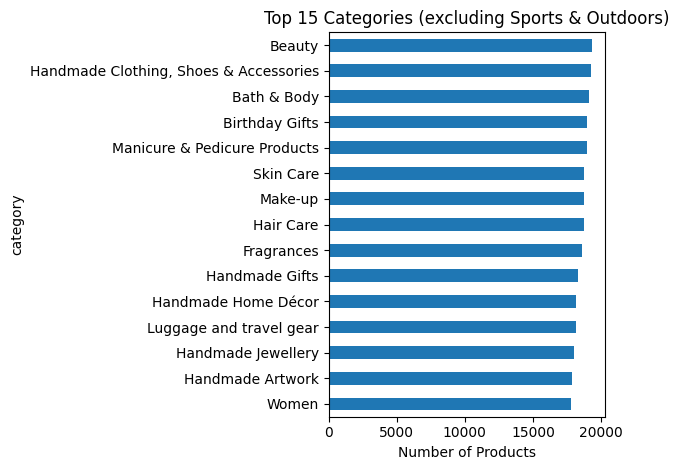

In [13]:
filtered = category_freq_table.drop('Sports & Outdoors')

filtered.head(15).sort_values().plot(kind='barh')

plt.title('Top 15 Categories (excluding Sports & Outdoors)')
plt.xlabel('Number of Products')
plt.tight_layout()
plt.show()

For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

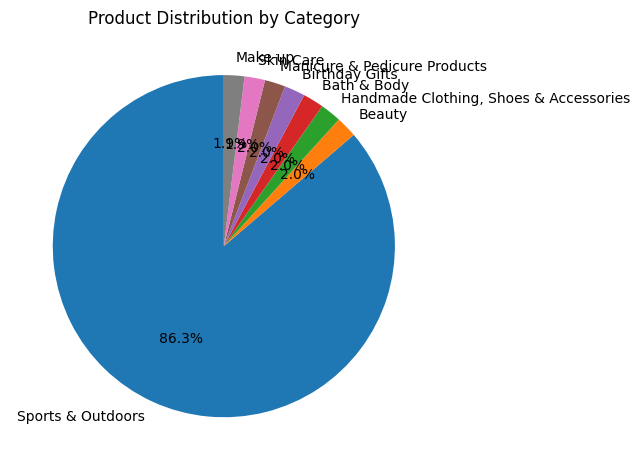

In [14]:
import matplotlib.pyplot as plt

top_n = 8
top = category_freq_table.head(top_n)

plot_data = top.copy()

plt.figure()
plot_data.plot(kind='pie', autopct='%1.1f%%', startangle=90)

plt.title('Product Distribution by Category')
plt.ylabel('')  # removes default "count" label
plt.tight_layout()
plt.show()

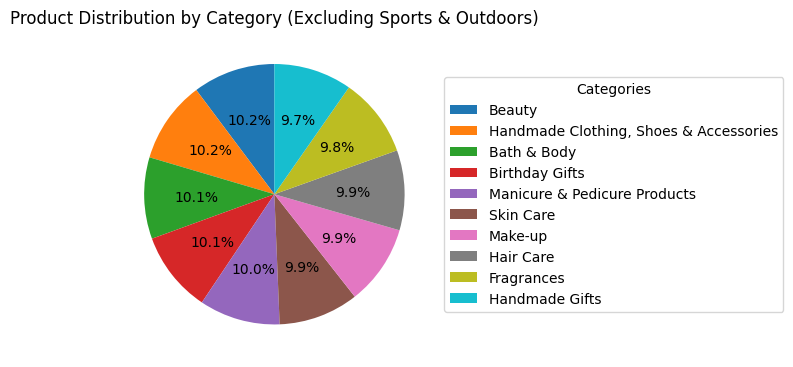

In [15]:
import matplotlib.pyplot as plt

# Remove dominant category
filtered = category_freq_table.drop('Sports & Outdoors')

# Take top categories from remaining data (to avoid clutter)
top_n = 10
plot_data = filtered.head(top_n)

plt.figure(figsize=(7,7))

plt.pie(
    plot_data,
    autopct='%1.1f%%',
    startangle=90
)

plt.legend(plot_data.index, title="Categories", loc="center left", bbox_to_anchor=(1, 0.5))

plt.title('Product Distribution by Category (Excluding Sports & Outdoors)')
plt.ylabel('')
plt.tight_layout()
plt.show()

**Part 2: Delving into Product Pricing**
Business Question: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

In [16]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

In [35]:
df['price'].value_counts

<bound method IndexOpsMixin.value_counts of 0          21.99
1          23.99
2          21.99
3          31.99
4          17.99
           ...  
2443646    22.34
2443647    97.99
2443648    52.99
2443649    79.99
2443650    53.99
Name: price, Length: 2443651, dtype: float64>

creating bins

In [17]:
bins = [0, 50, 100, 200, 500, 1000, float('inf')]
labels = ['0-50', '50-100', '100-200', '200-500', '500-1000', '1000+']

df['price_range'] = pd.cut(df['price'], bins=bins, labels=labels)
df['price_range'].value_counts().sort_index()

price_range
0-50        1877765
50-100       238612
100-200      133238
200-500      106511
500-1000      48391
1000+         39114
Name: count, dtype: int64

**Insights:**
The 0–50 range dominates massively
There is a long tail of expensive products, but they are much fewer

** 1.Measures of Centrality:**

Calculate the mean, median, and mode for the price of products.

In [18]:
df['price'].mean()

np.float64(89.24380943923663)

In [19]:
df['price'].median()

np.float64(19.09)

In [39]:
df['price'].mode()

0    9.99
Name: price, dtype: float64

Insights:
Mean ≫ Median ≫ Mode
This is positively skewed distribution

Most products are very cheap (around 10–20 range)
The most common price is ~9.99 (mode)
But a small number of very expensive products are pulling the average up to 89.2

What's the average price point of products listed? How does this compare with the most common price point (mode)?

In [20]:
print("Average price: ", df['price'].mean())
print("Most common price: ", df['price'].mode())

Average price:  89.24380943923663
Most common price:  0    9.99
Name: price, dtype: float64


Insight: Although the average listed product costs about 89, the typical product is actually priced around 10. This shows that high-priced items are rare but significantly increase the overall average.

**2.Measures of Dispersion:**
Determine the variance, standard deviation, range, and interquartile range for product price.

variance for price

In [21]:
variance = df['price'].var()
print("variance by formula: ", variance)

mean = df['price'].mean()

# manual calculation
deviation = df['price'] - mean
squared_deviation = deviation ** 2

variance = squared_deviation.mean()
print("calculated variance: " , variance)



variance by formula:  119445.48532254907
calculated variance:  119445.4364426209


standard deviation for price

In [50]:
std_deviation = df['price'].std()
print("Standard deviation by formula: ", std_deviation)


std_dev_Calculated = variance ** 0.5
print("Standard deviation calculated: ", std_dev_Calculated)


Standard deviation by formula:  345.60886175349884
Standard deviation calculated:  345.6087910378162


range for price

In [47]:
min_price = df['price'].min()
max_price = df['price'].max()

price_range  = max_price - min_price
print("Price range: ",price_range)

Price range:  100000.0


interquartile range for product price

How varied are the product prices? Are there any indicators of a significant spread in prices?

In [23]:
skewness = df['price'].skew()
print(skewness)

27.492977566280338


skewness of 27.49 is extremely high
that is because we have few very expensive products compared to the rest

**3.Visualizations:**
Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. If its hard to read these diagrams, think why this is, and explain how it could be solved..

<Axes: xlabel='price', ylabel='Count'>

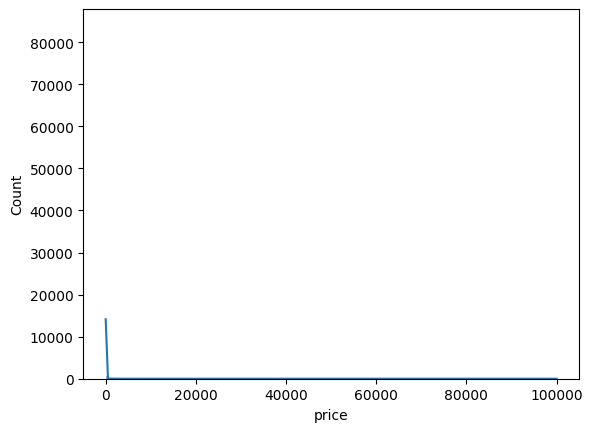

In [24]:
sns.histplot(df["price"], kde=True)

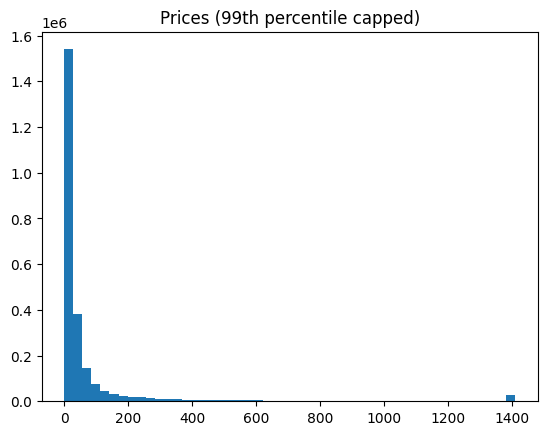

In [29]:
import numpy as np
import matplotlib.pyplot as plt

cap = np.percentile(df['price'], 99)
clipped = np.clip(df['price'], None, cap)

plt.hist(clipped, bins=50)
plt.title("Prices (99th percentile capped)")
plt.show()

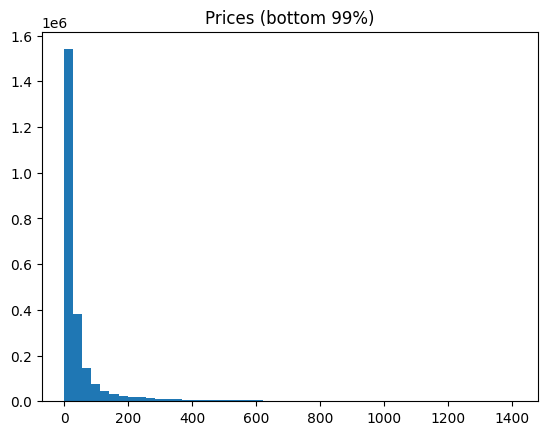

In [32]:
filtered = df['price'][df['price'] <= df['price'].quantile(0.99)]

plt.hist(filtered, bins=50)
plt.title("Prices (bottom 99%)")
plt.show()

In [31]:
print((df['price'] < 10).sum())

629239


It took more than 3 mins to load the histogram, which is i think very high load time
It may be because of high skewness, huge outliers
The histogram struggles because most values are tiny compared to a few massive ones.

Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.

<Axes: ylabel='price'>

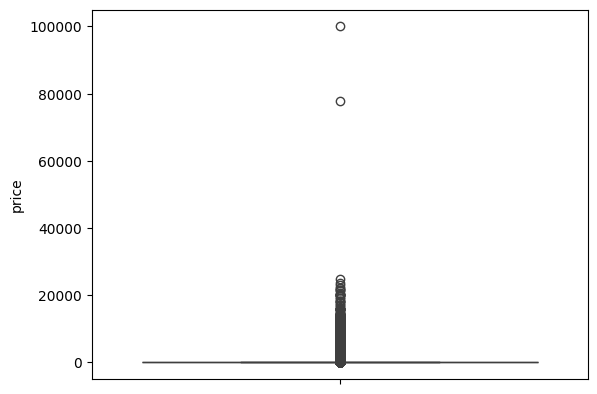

In [34]:
sns.boxplot(data=df['price'])

Median: 19.09
Upper Whisker: 99.99000000000001


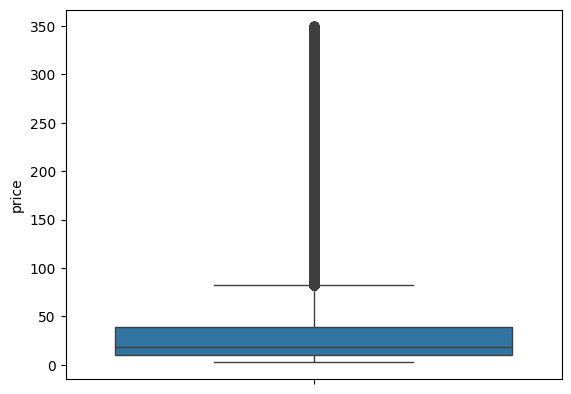

In [36]:
# Filter to see only data below the 95th percentile
q_low = df["price"].quantile(0.01)
q_hi  = df["price"].quantile(0.95)

df_filtered = df[(df["price"] < q_hi) & (df["price"] > q_low)]

# Re-plot
sns.boxplot(y=df_filtered["price"])

stats = df['price'].describe()
iqr = stats['75%'] - stats['25%']
upper_whisker = stats['75%'] + (1.5 * iqr)

print(f"Median: {stats['50%']}")
print(f"Upper Whisker: {upper_whisker}")

**Part 3: Unpacking Product Ratings**
Business Question: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

** 1.Measures of Centrality:**
Calculate the mean, median, and mode for the rating of products.

In [41]:
df['stars'].isnull().sum()

np.int64(0)

In [38]:
df['stars'].mean()

np.float64(2.152836472966065)

In [39]:
df['stars'].median()

np.float64(0.0)

In [40]:
df['stars'].mode()

0    0.0
Name: stars, dtype: float64

How do customers generally rate products? Is there a common trend?

If mean is 2.15 but median and mode are 0, data is extremely skewed.

Mode = 0: This is the most frequent value. More people (or data points) chose "0" than any other single number.

Median = 0: This is the most telling stat. It means that at least 50% of your entire dataset is 0. If you lined every entry up from smallest to largest, the person standing right in the middle is still at zero.

**2.Measures of Dispersion:**
Determine the variance, standard deviation, and interquartile range for product rating.

In [42]:
rating_variance = df['stars'].var()
print("rating variance: ", rating_variance)

rating variance:  4.817434029796862


In [43]:
rating_std = df['stars'].std()
print("rating standard deviation: ", rating_std)

rating standard deviation:  2.1948653785134207


interquartile range:

In [ ]:

ratings = df["stars"]

variance = ratings.var()
std_dev = ratings.std()
iqr = ratings.quantile(0.75) - ratings.quantile(0.25)

print("Variance:", variance)
print("Standard Deviation:", std_dev)
print("IQR:", iqr)

Are the ratings consistent, or is there a wide variation in customer feedback?

Your mean for rating is 2.15, and standard deviation is 2.19. This means the "average" deviation is almost as large as the mean itself. This confirms data is very "spread out" and inconsistent.

A standard deviation of 2 is massive. On a 5-point scale, a 2.0 deviation means your users are not in agreement.

A ton of people giving 0 (the mode), and a few people giving very high scores 5 that pull the mean up to 2.15.

** 3.Shape of the Distribution:**
Calculate the skewness and kurtosis for the rating column.

In [44]:
rating_skewness = df['stars'].skew()
print("Rating Skewness: ", rating_skewness)

Rating Skewness:  0.08120735761080985


In [45]:
rating_kurtosis = df['stars'].kurtosis()
print("Rating Kurtosis: ", rating_kurtosis)

Rating Kurtosis:  -1.9260061280432985


Are the ratings normally distributed, or do they lean towards higher or lower values?

In statistics, a negative kurtosis indicates a "Platykurtic" distribution. This means the distribution is extremely flat and has "thin tails" compared to a normal distribution.

A kurtosis this close to -2 suggests that almost nobody is actually giving a rating of 2 or 3.

Users (or data points) are polarized. don't have a "typical" user; have two distinct populations. If this is a product rating, people either don't use it at all (0) or they love it completely (high rating).

**4.Visualizations**
Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

<Axes: xlabel='stars', ylabel='Count'>

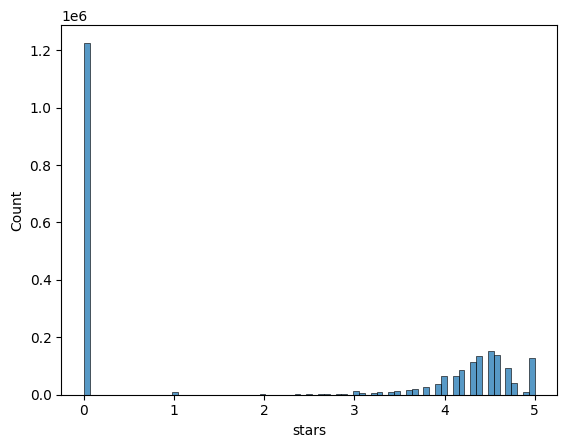

In [46]:
sns.histplot(data=df['stars'])

Rating zero is very common
The Count: over 1.2 million entries at exactly 0.

The Impact: This is why your Median and Mode are 0. More than half of your users (or items) have a 0-star rating. This "anchors" the statistics to the far left.

On the right side, have a beautiful, almost normal distribution centered around 4.5 stars.
The Crowd: There is a significant cluster of satisfied users between 4.0 and 5.0.

The Impact: This "success group" is what pulls your Mean up to 2.15. Without these high ratings, your mean would be near zero.